# Keypoint Detection: Pose Estimation with Four Models

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roboflow/supervision/blob/develop/docs/notebooks/keypoint-detection.ipynb)

A pose estimation model finds the joints of every person in an image: nose, shoulders, elbows, wrists, hips, knees and ankles. Each joint is a keypoint, an `(x, y)` position with a confidence score, and the joints of one person form a skeleton.

supervision stores them in `sv.KeyPoints`. Every model connector returns the same object, so the drawing and analysis code you write once works for all of them:

- `sv.KeyPoints.from_ultralytics` for Ultralytics YOLO pose models.
- `sv.KeyPoints.from_transformers` for Hugging Face Transformers pose models such as ViTPose.
- `sv.KeyPoints.from_inference`, `from_mediapipe`, `from_yolo_nas` and `from_detectron2` for other frameworks.
- RF-DETR needs no connector: its `predict` method already returns `sv.KeyPoints`.

This cookbook runs four models on the same photo of a group of children:

- **RF-DETR keypoint preview**: a one-stage DETR-style model that also predicts how uncertain each joint is, as a covariance that supervision can draw.
- **ViTPose-base**: a plain vision transformer that estimates joints inside person boxes, so it needs a detector in front of it.
- **ViTPose++-large**: a larger ViTPose trained on several pose datasets, using the same code as the base model.
- **YOLO26m-pose**: a one-stage model that finds people and their joints in one pass.

The last sections use the new `sv.ColorPalette` and `sv.ColorLookup` support of the keypoint annotators to colour a skeleton by person, by class or by joint, and `sv.joint_angles` with `sv.JointAngleAnnotator` to measure how far each person bends an elbow or a knee.

## Install required packages

`transformers` runs ViTPose and the RT-DETR person detector, `ultralytics` runs YOLO26 and `rfdetr` runs RF-DETR.

In [ ]:
! pip install -q transformers ultralytics rfdetr

Colouring keypoints with `sv.ColorLookup.KEYPOINT` and measuring joint angles with `sv.joint_angles` ship in supervision `0.32.0`. Until it is released, install it from the `develop` branch. This is a separate step with `--no-deps` because `rfdetr` and other packages pin their own supervision range.

In [ ]:
! pip install -q --no-deps "supervision @ git+https://github.com/roboflow/supervision.git@develop"

Later sections compare models and draw results, so everything is imported in one place.

In [1]:
import urllib.request

import numpy as np
import torch
from PIL import Image
from scipy.optimize import linear_sum_assignment
from rfdetr import RFDETRKeypointPreview
from transformers import (
    AutoProcessor,
    RTDetrForObjectDetection,
    VitPoseForPoseEstimation,
)
from ultralytics import YOLO

import supervision as sv

print(sv.__version__)

0.32.0.dev0


## Download the sample image

Pose models are easiest to compare on a crowded scene, so this photo shows a group of children on a tennis court. People fill the frame, stand in two rows and overlap, which is where pose models disagree most. It comes from the COCO validation set.

In [2]:
image_url = "http://images.cocodataset.org/val2017/000000001000.jpg"
image_path = "tennis-group.jpg"
urllib.request.urlretrieve(image_url, image_path)

The models take a Pillow image, and supervision annotators take a BGR array, so the photo is kept in both forms.

In [3]:
pil_image = Image.open(image_path).convert("RGB")
image = sv.pillow_to_cv2(pil_image)
height, width = image.shape[:2]
print(f"Image size: {width}x{height}")

Image size: 640x480


The next plot shows the unannotated photo, as a reference for judging the skeletons below.

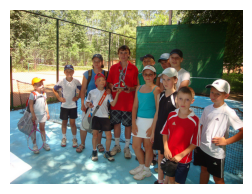

In [4]:
sv.plot_image(image, size=(3, 2.3))

More than ten children stand in two rows. The front row is fully visible, while the children in the back row are partly hidden behind them. Hidden bodies are the hard case for any pose model.

## Shared setup

The Hugging Face models run on the device chosen here, and Ultralytics picks its own.

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on {device}")

Running on cpu


All three models predict the 17 COCO joints, so one edge annotator and one vertex annotator serve them all. `EdgeAnnotator` picks the COCO skeleton on its own when a person has 17 keypoints. Each person gets a colour by index, so neighbouring skeletons are easy to tell apart.

In [6]:
edge_annotator = sv.EdgeAnnotator(
    color=sv.ColorPalette.DEFAULT, thickness=2, color_lookup=sv.ColorLookup.INDEX
)
vertex_annotator = sv.VertexAnnotator(
    color=sv.ColorPalette.DEFAULT, radius=3, color_lookup=sv.ColorLookup.INDEX
)


def annotate(scene: np.ndarray, key_points: sv.KeyPoints) -> np.ndarray:
    """Draw the skeleton edges and joints of every person on a copy of the scene."""
    annotated = edge_annotator.annotate(scene.copy(), key_points)
    return vertex_annotator.annotate(annotated, key_points)

## RF-DETR keypoints

RF-DETR is a DETR-style detector, and its keypoint preview model finds people and their 17 joints in one pass, so no separate detector is needed. It needs no connector: `predict` already returns `sv.KeyPoints`, with the weights of the pretrained COCO model downloaded on first use. The threshold drops detections the model is not confident about.

In [7]:
rfdetr = RFDETRKeypointPreview()

`predict` takes the Pillow image directly.

In [8]:
rfdetr_key_points = rfdetr.predict(pil_image, threshold=0.5)

`KeyPoints` is a container of NumPy arrays: `xy` holds the positions as `(people, joints, 2)`, `keypoint_confidence` holds one score per joint and `class_id` holds the class of each person. Printing the shapes shows what the object stores.

In [9]:
print(f"xy: {rfdetr_key_points.xy.shape}")
print(f"keypoint_confidence: {rfdetr_key_points.keypoint_confidence.shape}")
print(f"class_id: {rfdetr_key_points.class_id}")

xy: (11, 17, 2)
keypoint_confidence: (11, 17)
class_id: [1 1 1 1 1 1 1 1 1 1 1]


The next plot shows whether the skeletons follow the bodies of the children, including those half hidden behind others.

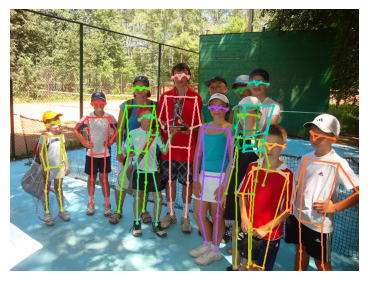

In [10]:
sv.plot_image(annotate(image, rfdetr_key_points), size=(4.5, 3.4))

RF-DETR finds 11 people in one pass and draws the front row cleanly. Its threshold is the confidence of the model itself, a different one from the detector below, so the people counts are not strictly comparable.

### Covariance: how sure is each joint?

Besides the position, RF-DETR predicts how uncertain each joint is. supervision stores it in `key_points.data["covariance"]` as one `2x2` matrix per joint in pixels, which describes an ellipse around the joint. A small round ellipse means the model is sure where the joint is, and a large or stretched one means it is not.

In [11]:
covariance = rfdetr_key_points.data["covariance"]
print(f"covariance: {covariance.shape}")

covariance: (11, 17, 2, 2)


The longest semi-axis of each ellipse, in pixels, is one number per joint. The median over the joints of a person ranks the people by how sure the model is about them.

In [12]:
uncertainty = np.sqrt(np.linalg.eigvalsh(covariance)[..., -1])
person_uncertainty = np.median(uncertainty, axis=1)
ranking = np.argsort(person_uncertainty)
most_certain, least_certain = ranking[0], ranking[-1]
print(f"most certain person: {person_uncertainty[most_certain]:.1f}px")
print(f"least certain person: {person_uncertainty[least_certain]:.1f}px")

most certain person: 10.3px
least certain person: 81.2px


`VertexEllipseOutlineAnnotator` draws the ellipses at one and two standard deviations. `max_axis` caps the size of the rare huge ellipse, so it cannot cover the picture.

In [13]:
ellipse_annotator = sv.VertexEllipseOutlineAnnotator(
    sigma=(1.0, 2.0),
    color=(sv.Color.YELLOW, sv.Color.RED),
    thickness=1,
    max_axis=40,
)

The next plot shows the most certain person on the left and the least certain person on the right. The question is where the uncertainty comes from.

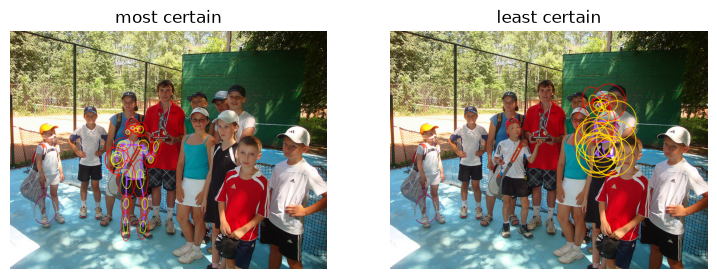

In [14]:
panels = []
for person in (most_certain, least_certain):
    single = rfdetr_key_points[[person]]
    panel = edge_annotator.annotate(image.copy(), single)
    panels.append(ellipse_annotator.annotate(panel, single))
sv.plot_images_grid(
    images=panels,
    grid_size=(1, 2),
    titles=["most certain", "least certain"],
    size=(9, 3.4),
)

The most certain person is a child on the left of the group, whose ellipses are small and tight around the joints, with a median semi-axis of 10.3px. The least certain person is hidden behind other children in the middle of the group, and its ellipses are wide, with a median of 81.2px. Several are cut at the `max_axis` of 40px. The model reports a joint it cannot see, and the covariance is what tells that estimate apart from a measured one.

## ViTPose

ViTPose estimates joints inside a person box, so it is a top-down model: a detector finds the people first, and the pose model then looks at each box on its own. This costs a second model, but the pose network sees every person at the same scale.

The detector is RT-DETR from Transformers. Its checkpoint predicts the 80 COCO classes, so the person class `0` is the only one kept.

In [15]:
detector_name = "PekingU/rtdetr_r50vd_coco_o365"
detector_processor = AutoProcessor.from_pretrained(detector_name)
detector = RTDetrForObjectDetection.from_pretrained(detector_name).to(device)

Gradients are not needed for inference, so disabling them saves memory.

In [16]:
inputs = detector_processor(images=pil_image, return_tensors="pt").to(device)
with torch.no_grad():
    outputs = detector(**inputs)

Post-processing turns the raw outputs into boxes in the pixel coordinates of the photo. `from_transformers` converts them to `sv.Detections`, the same type the detection cookbooks use. The threshold of `0.5` keeps confident people only.

In [17]:
detector_results = detector_processor.post_process_object_detection(
    outputs, target_sizes=torch.tensor([(height, width)]), threshold=0.5
)
detections = sv.Detections.from_transformers(
    detector_results[0], id2label=detector.config.id2label
)
people = detections[detections.class_id == 0]
print(f"{len(people)} people, confidence {np.round(people.confidence, 2)}")

13 people, confidence [       0.95        0.95        0.94        0.94        0.93        0.92        0.91        0.89        0.87        0.87         0.7        0.52        0.51]


ViTPose reads boxes in `xywh` format, so the `xyxy` boxes are converted once.

In [18]:
person_boxes = sv.xyxy_to_xywh(people.xyxy)

The base model is the smaller of the two ViTPose checkpoints used here.

In [19]:
vitpose_name = "usyd-community/vitpose-base-simple"
vitpose_processor = AutoProcessor.from_pretrained(vitpose_name)
vitpose = VitPoseForPoseEstimation.from_pretrained(vitpose_name).to(device)

The processor crops and resizes each box, so the model receives one batch entry per person.

In [20]:
inputs = vitpose_processor(pil_image, boxes=[person_boxes], return_tensors="pt").to(
    device
)
with torch.no_grad():
    outputs = vitpose(**inputs)

Post-processing maps the predicted heatmaps back to positions in the original photo. The result is a list with one entry per image, each holding one dict per person.

In [21]:
vitpose_results = vitpose_processor.post_process_pose_estimation(
    outputs, boxes=[person_boxes]
)

`from_transformers` takes the per-image list. Every person gets class id `0`, because the model only reports poses of one object category.

In [22]:
vitpose_key_points = sv.KeyPoints.from_transformers(
    vitpose_results[0], num_keypoints=len(vitpose.config.id2label)
)
print(f"xy: {vitpose_key_points.xy.shape}")

xy: (13, 17, 2)


The next plot shows whether a top-down model draws the same skeletons as the one-stage model above.

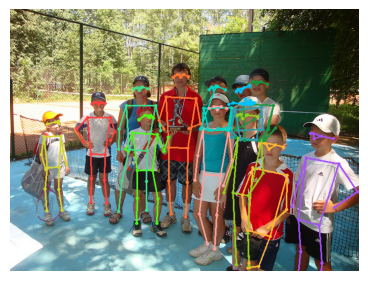

In [23]:
sv.plot_image(annotate(image, vitpose_key_points), size=(4.5, 3.4))

The detector found 13 people, so ViTPose draws 13 skeletons. The count comes from the detector: its two lowest confidences are 0.52 and 0.51, so a threshold above 0.52 would drop two children before the pose model sees them.

## ViTPose++

ViTPose++ is the larger follow-up, trained on several pose datasets at once. It keeps one expert per dataset inside the model, so the forward pass needs to know which expert to use. Index `0` selects the COCO expert, which predicts the same 17 joints as the other models. The processor, post-processing and supervision call do not change.

In [24]:
vitpose_plus_name = "usyd-community/vitpose-plus-large"
vitpose_plus_processor = AutoProcessor.from_pretrained(vitpose_plus_name)
vitpose_plus = VitPoseForPoseEstimation.from_pretrained(vitpose_plus_name).to(device)

`dataset_index` holds one value per person in the batch.

In [25]:
inputs = vitpose_plus_processor(
    pil_image, boxes=[person_boxes], return_tensors="pt"
).to(device)
dataset_index = torch.zeros(len(person_boxes), dtype=torch.long, device=device)
with torch.no_grad():
    outputs = vitpose_plus(**inputs, dataset_index=dataset_index)

Post-processing and conversion are identical to the base model.

In [26]:
vitpose_plus_results = vitpose_plus_processor.post_process_pose_estimation(
    outputs, boxes=[person_boxes]
)
vitpose_plus_key_points = sv.KeyPoints.from_transformers(
    vitpose_plus_results[0], num_keypoints=len(vitpose_plus.config.id2label)
)
print(f"xy: {vitpose_plus_key_points.xy.shape}")

xy: (13, 17, 2)


The next plot shows what the larger model changes compared with the base one.

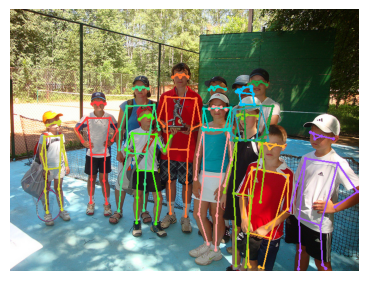

In [27]:
sv.plot_image(annotate(image, vitpose_plus_key_points), size=(4.5, 3.4))

The larger model works on the same 13 boxes, so it draws 13 skeletons too, and at this scale it looks like the base model. The differences are a few pixels, which the comparison below measures.

## YOLO26 pose

Ultralytics ships pose models in its YOLO26 family, in five sizes from `n` to `x`. They find the people and their joints in one forward pass, so no separate detector is needed. The medium model is a good size to start with.

In [28]:
yolo = YOLO("yolo26m-pose.pt")

Calling the model returns one result per image. The result holds the boxes, and the joints in `keypoints`.

In [29]:
yolo_result = yolo(pil_image, verbose=False)[0]
print(yolo_result.keypoints.xy.shape)

torch.Size([12, 17, 2])


`from_ultralytics` takes the result as it is. Nothing else is needed.

In [30]:
yolo_key_points = sv.KeyPoints.from_ultralytics(yolo_result)

The next plot shows how the Ultralytics model draws the same skeletons.

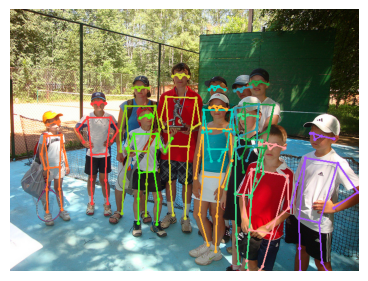

In [31]:
sv.plot_image(annotate(image, yolo_key_points), size=(4.5, 3.4))

YOLO26m finds 12 people in one pass, without a separate detector. The skeletons of the front row follow the bodies. In the crowded middle the skeletons of neighbouring children cross each other, because their arms and legs overlap in the picture.

## Compare the models

The four models share one output type, so a side-by-side view takes one list comprehension. The next plot answers where they visibly disagree.

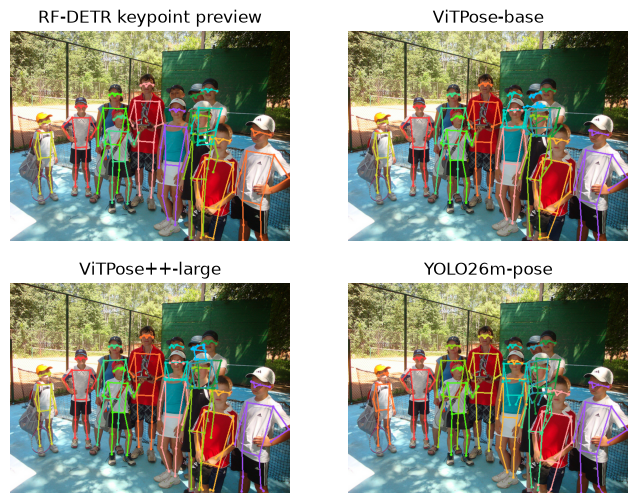

In [32]:
results = {
    "RF-DETR keypoint preview": rfdetr_key_points,
    "ViTPose-base": vitpose_key_points,
    "ViTPose++-large": vitpose_plus_key_points,
    "YOLO26m-pose": yolo_key_points,
}

sv.plot_images_grid(
    images=[annotate(image, key_points) for key_points in results.values()],
    grid_size=(2, 2),
    titles=list(results),
    size=(8, 6),
)

All four models agree on the front row. They differ in the crowded middle and in the back row, and in how many people they find: 11 for RF-DETR, 13 for both ViTPose models and 12 for YOLO26m.

A picture hides how large the differences are in pixels. To measure it, each person from one model has to be matched to the same person from another model, because the models neither return people in the same order nor find the same number of people. The centre of the confident joints of a person is a stable key, and the Hungarian algorithm picks the pairing with the smallest total distance.

In [33]:
def person_centers(key_points: sv.KeyPoints) -> np.ndarray:
    """Return the mean position of the confident joints of every person."""
    weights = (key_points.keypoint_confidence > 0.5)[..., None]
    return (key_points.xy * weights).sum(axis=1) / np.maximum(weights.sum(axis=1), 1)


def match_people(reference: sv.KeyPoints, other: sv.KeyPoints) -> tuple:
    """Pair each person of ``other`` with the closest person of ``reference``."""
    distances = np.linalg.norm(
        person_centers(reference)[:, None, :] - person_centers(other)[None, :, :],
        axis=-1,
    )
    return linear_sum_assignment(distances)

For every matched pair, the distance between the same joint in both models is measured in pixels. Only joints that both models are confident about count, because a model reports a position even for a joint it cannot see.

In [34]:
def joint_errors(reference: sv.KeyPoints, other: sv.KeyPoints) -> np.ndarray:
    """Return the pixel distance of every shared confident joint, NaN elsewhere."""
    rows, columns = match_people(reference, other)
    distance = np.linalg.norm(reference.xy[rows] - other.xy[columns], axis=-1)
    confident = (reference.keypoint_confidence[rows] > 0.5) & (
        other.keypoint_confidence[columns] > 0.5
    )
    return np.where(confident, distance, np.nan)

ViTPose++-large is the reference, as the largest of the four models.

In [35]:
joint_names = [
    "nose",
    "left eye",
    "right eye",
    "left ear",
    "right ear",
    "left shoulder",
    "right shoulder",
    "left elbow",
    "right elbow",
    "left wrist",
    "right wrist",
    "left hip",
    "right hip",
    "left knee",
    "right knee",
    "left ankle",
    "right ankle",
]

reference = vitpose_plus_key_points
errors = {
    name: joint_errors(reference, key_points)
    for name, key_points in results.items()
    if key_points is not reference
}
assert all(np.isfinite(distance).any() for distance in errors.values())

The printout gives, for each model, how many people it found, how many of them were matched to the reference, the mean error and the three joints with the largest error.

In [36]:
print(f"{'ViTPose++-large (reference)':<26} {len(reference)} people")
for name, distance in errors.items():
    valid = np.isfinite(distance)
    per_joint = np.nansum(distance, axis=0) / np.maximum(valid.sum(axis=0), 1)
    worst = np.argsort(per_joint)[::-1][:3]
    print(
        f"{name:<26} {len(results[name])} people, {len(distance)} matched, "
        f"mean {np.nanmean(distance):.1f}px"
    )
    for joint in worst:
        print(f"    {joint_names[joint]:<15} {per_joint[joint]:.1f}px")

ViTPose++-large (reference) 13 people
RF-DETR keypoint preview   11 people, 11 matched, mean 1.8px
    right hip       3.9px
    left hip        3.4px
    left ankle      3.0px
ViTPose-base               13 people, 13 matched, mean 1.7px
    left wrist      3.2px
    left elbow      2.9px
    left ankle      2.9px
YOLO26m-pose               12 people, 12 matched, mean 2.4px
    left wrist      4.6px
    right ankle     4.2px
    left ankle      3.9px


On the joints that both models are confident about, the three models stay within about 2px of the reference on average. The largest errors sit on the arms and feet for YOLO26m and ViTPose-base: the wrists, the elbows and the ankles. RF-DETR differs most on the hips. These numbers measure how much the models agree with the largest of them, not how accurate any of them is, because the photo has no ground-truth annotation. They also ignore the joints a model is not confident about and the people it did not match, so they say nothing about the crowded middle where the models differ most.

## Colour keypoints with `ColorPalette` and `ColorLookup`

So far every skeleton was coloured by person. The vertex, edge and label annotators accept an `sv.ColorPalette` and a `color_lookup` that decides which palette entry each keypoint receives:

- `sv.ColorLookup.INDEX`: one colour per person, in the order the model returned them.
- `sv.ColorLookup.CLASS`: one colour per class id. All people share class `0` here, so they share one colour.
- `sv.ColorLookup.KEYPOINT`: one colour per joint, so the left wrist has the same colour on every person.

`sv.ColorLookup.TRACK` is not available for keypoints and raises an error when the annotator is created.

The next plot colours the joints of the ViTPose++ result by index in the first panel, by class in the second and by joint in the third. The question is which view answers which question about a pose.

In [37]:
lookups = {
    "INDEX": sv.ColorLookup.INDEX,
    "CLASS": sv.ColorLookup.CLASS,
    "KEYPOINT": sv.ColorLookup.KEYPOINT,
}

A palette with one entry per joint makes the `KEYPOINT` lookup readable, so a gradient with 17 colours is built from a Matplotlib colour map.

In [38]:
joint_palette = sv.ColorPalette.from_matplotlib("turbo", len(joint_names))

The edges stay neutral in the third panel, so the joint colours stand out. The other two panels reuse the palette for the edges.

In [39]:
def annotate_lookup(
    scene: np.ndarray,
    key_points: sv.KeyPoints,
    palette: sv.ColorPalette,
    color_lookup: sv.ColorLookup,
) -> np.ndarray:
    """Draw skeletons whose edges and joints are coloured by the given lookup."""
    edge_color = (
        sv.Color.WHITE if color_lookup == sv.ColorLookup.KEYPOINT else palette
    )
    edges = sv.EdgeAnnotator(color=edge_color, thickness=2, color_lookup=color_lookup)
    vertices = sv.VertexAnnotator(color=palette, radius=4, color_lookup=color_lookup)
    return vertices.annotate(edges.annotate(scene.copy(), key_points), key_points)

The panels use the default palette for `INDEX` and `CLASS`, and the 17-colour gradient for `KEYPOINT`.

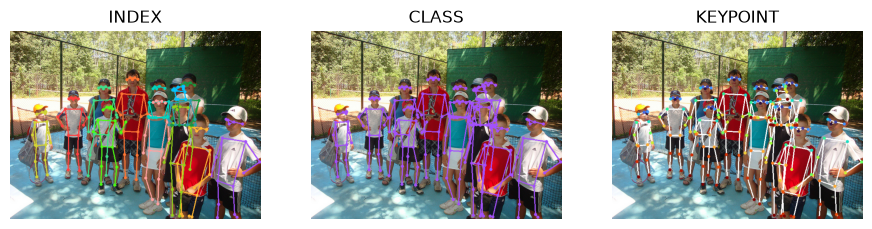

In [40]:
sv.plot_images_grid(
    images=[
        annotate_lookup(
            image,
            vitpose_plus_key_points,
            joint_palette if lookup == sv.ColorLookup.KEYPOINT else sv.ColorPalette.DEFAULT,
            lookup,
        )
        for lookup in lookups.values()
    ],
    grid_size=(1, 3),
    titles=list(lookups),
    size=(11, 3.2),
)

Each lookup answers a different question. `INDEX` gives every person one colour, which keeps skeletons apart when people overlap. `CLASS` gives all of them the first palette colour, because every person has class `0`, so it only helps when a model reports several classes. `KEYPOINT` gives each joint its own colour on every person, so a swapped left and right limb or a joint pulled onto the wrong body part stands out at once.

`VertexLabelAnnotator` takes the same arguments and writes a label next to each joint. The label list follows the joint order and each label is coloured by the joint it names. Labelling all 17 joints of every child overlaps, so only three joints of the three most confident people are kept: the nose, the left hip and the left ankle sit far apart on a standing person.

In [41]:
label_joints = [0, 11, 15]
label_key_points = vitpose_plus_key_points[:3][:, label_joints]
labels = [joint_names[joint] for joint in label_joints]

The palette is shortened to match the number of joints kept, so each one keeps a distinct colour.

In [42]:
label_palette = sv.ColorPalette.from_matplotlib("turbo", len(label_joints))
label_annotator = sv.VertexLabelAnnotator(
    color=label_palette,
    text_color=sv.Color.WHITE,
    text_scale=0.4,
    border_radius=4,
    color_lookup=sv.ColorLookup.KEYPOINT,
)

The next plot shows the three joints of three people, each labelled with its name and coloured by joint.

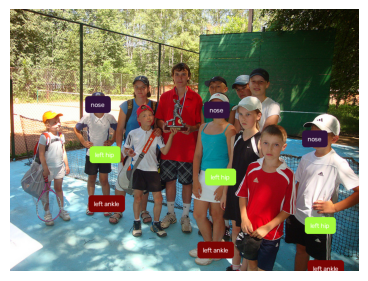

In [43]:
sv.plot_image(
    label_annotator.annotate(image.copy(), label_key_points, labels=labels),
    size=(4.5, 3.4),
)

Each label names its joint and takes the colour of that joint: the nose is dark purple, the left hip green and the left ankle dark red. A label is centred on its joint and covers it, so label only the joints you need to read.

## Measure joint angles

A skeleton says where the joints are. Many questions are about how far a joint bends: how deep a squat goes, or whether an arm is straight. `sv.joint_angles` answers them from any `sv.KeyPoints`. A joint is a `JointAngle`: a name and three positions along the second axis of `xy`, called `start`, `joint` and `end`. The angle is measured at `joint`, between the rays towards `start` and towards `end`, from 0 to 180 degrees.

<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 380 270" width="380" height="270" role="img" aria-labelledby="joint-angle-title">
  <title id="joint-angle-title">A joint angle is measured at the joint, between the rays to start and to end</title>
  <g fill="none" stroke="#6b7280" stroke-width="3" stroke-linecap="round">
    <line x1="190" y1="170" x2="70" y2="50"/>
    <line x1="190" y1="170" x2="320" y2="230"/>
  </g>
  <path d="M161.7 141.7 A40 40 0 0 1 226.3 186.8" fill="none" stroke="#8b5cf6" stroke-width="4" stroke-linecap="round"/>
  <g fill="#8b5cf6">
    <circle cx="70" cy="50" r="7"/>
    <circle cx="190" cy="170" r="7"/>
    <circle cx="320" cy="230" r="7"/>
  </g>
  <g font-family="sans-serif" font-size="18" fill="#6b7280" text-anchor="middle">
    <text x="70" y="34">start</text>
    <text x="172" y="204">joint</text>
    <text x="320" y="260">end</text>
  </g>
  <text x="238" y="106" font-family="sans-serif" font-size="22" font-weight="bold" fill="#8b5cf6" text-anchor="middle">160°</text>
</svg>

The figure shows a joint of 160°: `start` and `end` are the points the two rays run to, and the arc marks the angle at `joint`.

The positions follow the COCO layout that all four models share. The left elbow is shoulder 5, elbow 7 and wrist 9, and the left knee is hip 11, knee 13 and ankle 15. The right side uses 6, 8, 10 and 12, 14, 16.

In [44]:
from supervision.key_points.angles import JointAngle

joints = [
    JointAngle("left_elbow", start=5, joint=7, end=9),
    JointAngle("right_elbow", start=6, joint=8, end=10),
    JointAngle("left_knee", start=11, joint=13, end=15),
    JointAngle("right_knee", start=12, joint=14, end=16),
]

`joint_angles` returns one row per person and one column per joint, in degrees. YOLO26 is used here because a single call finds the people and their joints.

In [45]:
angles = sv.joint_angles(yolo_key_points, joints)
print(f"angles: {angles.shape}")
print(angles[:3].round().astype(int))
print(f"measured: {np.isfinite(angles).sum()} of {angles.size}")

angles: (12, 4)
[[ 89 177 155 180]
 [120 112 173 177]
 [129 160 166 171]]
measured: 48 of 48


All 48 angles are numbers, even for the children in the back row, whose legs are hidden behind the front row. A model places every joint somewhere, however unsure it is, and `joint_angles` reads positions, not confidence. It leaves out only joints hidden by `KeyPoints.visible`, so the unsure joints are hidden first. Marking joints below 0.5 confidence as not visible turns 18 of the 48 angles into `NaN`, a missing value instead of a guess, and five of the twelve people keep all four. The two extremes among those five are the person with the most bent elbow and the person whose elbows are straightest.

In [46]:
yolo_key_points.visible = yolo_key_points.keypoint_confidence > 0.5
confident_angles = sv.joint_angles(yolo_key_points, joints)
print(f"measured: {np.isfinite(confident_angles).sum()} of {confident_angles.size}")
complete = np.isfinite(confident_angles).all(axis=1)
print(f"people with all four joints: {complete.sum()} of {len(complete)}")
bend = np.where(complete, confident_angles[:, :2].min(axis=1), np.nan)
bent_arm, straight_arm = np.nanargmin(bend), np.nanargmax(bend)
print(bent_arm, straight_arm, confident_angles[[bent_arm, straight_arm]].round().astype(int))

measured: 30 of 48
people with all four joints: 5 of 12
6 4 [[ 53 126 166 179]
 [158 178 177 160]]


`JointAngleAnnotator` draws an arc inside each joint and labels it with its angle in degrees, such as `126°`. It skips every joint whose angle is `NaN`. The plot zooms in on the two people picked above, because the labels would crowd each other on the full photo.

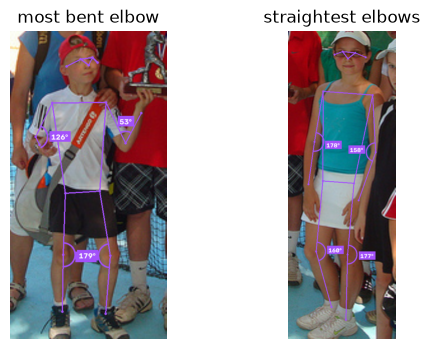

In [47]:
angle_annotator = sv.JointAngleAnnotator(
    angles=joints, color=sv.Color.ROBOFLOW, radius=28, text_scale=0.6, text_thickness=2
)


def zoom_on(person: int, scale: int = 3) -> np.ndarray:
    """Draw one person's skeleton and joint angles on an enlarged crop around them."""
    single = yolo_key_points[[person]]
    x_min, y_min = np.maximum(single.xy[0].min(axis=0) - 20, 0).astype(int)
    x_max, y_max = (single.xy[0].max(axis=0) + 20).astype(int)
    crop = sv.scale_image(image[y_min:y_max, x_min:x_max], scale)
    zoomed = sv.KeyPoints(
        xy=(single.xy - [x_min, y_min]) * scale,
        class_id=single.class_id,
        visible=single.visible,
    )
    return angle_annotator.annotate(annotate(crop, zoomed), zoomed)


sv.plot_images_grid(
    images=[zoom_on(bent_arm), zoom_on(straight_arm)],
    grid_size=(1, 2),
    titles=["most bent elbow", "straightest elbows"],
    size=(6, 4),
)

The boy in the white shirt bends his left elbow to 53 degrees and his right elbow to 126, while the girl in the turquoise top has elbows at 158 and 178 degrees, almost straight. Her knees read 177 and 160 degrees.

These are angles in the image plane, so a limb that points at the camera reads straighter than it is. They describe how the pose looks in the photo, not the 3D angle of the joint.

## What next

- Try `sv.VertexEllipseAreaAnnotator` and `sv.VertexEllipseHaloAnnotator` for other looks at the RF-DETR covariance.
- Hide uncertain joints: `KeyPoints` accepts a boolean `visible` array of shape `(people, joints)`, and the annotators skip joints marked `False`.
- Send the keypoints through `key_points.as_detections()` to get a box around each skeleton and use the usual `sv.Detections` filters and trackers.
- Pass a custom `edges` argument to `sv.EdgeAnnotator` for a model with a different skeleton, such as a hand or a face.
- Measure other joints: `JointAngle` takes any three positions, so a hip, shoulder or neck angle is one more entry in `joints`. On video, call `sv.joint_angles` on every frame to follow an angle over time.